# RFM (Recency, Frequency and Monetary) segmentation

## RFM sur les 3% qui effectuent plusieurs commandes pour évaluer leur engagement

/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


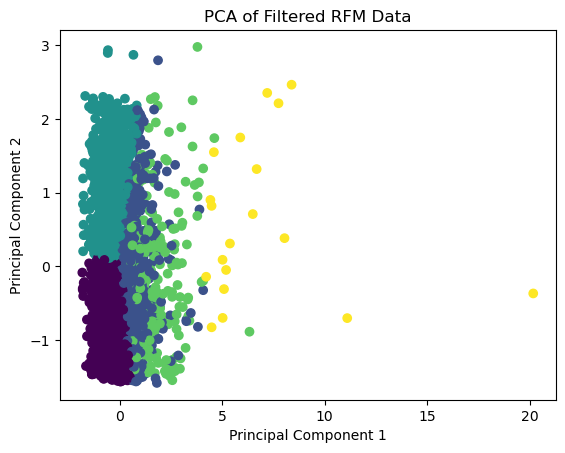

Davies-Bouldin Score: 0.8969995326771217
Silhouette Score: 0.3728985284045568


In [5]:
# Import necessary libraries
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set display options
pd.set_option('display.max_columns', None)  
pd.set_option('display.max_rows', 100) 
pd.set_option('max_colwidth', 100) 

# Load data
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# Merge data
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Aggregate by customer
data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Rename columns
data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)


# Convert to datetime
orders_reviews['order_purchase_timestamp'] = pd.to_datetime(orders_reviews['order_purchase_timestamp'])

# Calculate the last order date for each customer
data['last_order_date'] = orders_reviews.groupby('customer_unique_id')['order_purchase_timestamp'].transform('max')

# Get the most recent order date in the entire dataset using 'orders_reviews' DataFrame
max_order_date = orders_reviews['order_purchase_timestamp'].max().date()

# Now, filter the 'data' DataFrame for customers with more than one order
data = data[data["total_orders"] > 1]

# Calculate 'Recency'
data['Recency'] = (max_order_date - data['last_order_date'].dt.date).dt.days


# Calculate 'Frequency' and 'MonetaryValue_log'
data['Frequency'] = data['total_orders']
data['MonetaryValue_log'] = np.log(data['total_payment_value'] + 1)  # Adding 1 to handle zero values

# Scaling features
rfm_features = ['Recency', 'Frequency', 'MonetaryValue_log']
scaler = StandardScaler()
rfm_data_scaled = scaler.fit_transform(data[rfm_features])
# Clustering
kmeans = KMeans(n_clusters=5, random_state=42)
data['RFM_Cluster'] = kmeans.fit_predict(rfm_data_scaled)

# Principal Component Analysis (PCA) for visualization
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(rfm_data_scaled)
principalDf = pd.DataFrame(data=principalComponents, columns=['PC1', 'PC2'])

principalDf['RFM_Cluster'] = data['RFM_Cluster'].values

plt.scatter(principalDf['PC1'], principalDf['PC2'], c=principalDf['RFM_Cluster'])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Filtered RFM Data')
plt.show()
# Davies-Bouldin Score
db_score = davies_bouldin_score(rfm_data_scaled, data['RFM_Cluster'])
print(f'Davies-Bouldin Score: {db_score}')

# Silhouette Score
silhouette_avg = silhouette_score(rfm_data_scaled, data['RFM_Cluster'])
print(f'Silhouette Score: {silhouette_avg}')

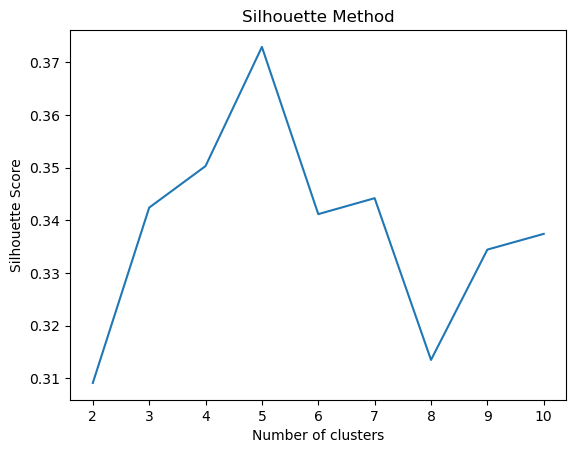

In [2]:
# Calculate Silhouette Score for different numbers of clusters
silhouette_scores = []
for i in range(2, 11): 
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(rfm_data_scaled)
    silhouette_avg = silhouette_score(rfm_data_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Plotting the Silhouette graph
plt.figure()
plt.plot(range(2, 11), silhouette_scores)
plt.title('Silhouette Method')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()


In [ ]:
rfm_data_scaled_df = pd.DataFrame(rfm_data_scaled, columns=rfm_features)
rfm_data_scaled_df

## RFM sur l'ensemble de la population

/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


RFM_Cluster     Recency             Frequency           MonetaryValue  \
                     mean         std      mean       std          mean   
0           0  426.558012   88.538355  1.000483  0.021979    148.548584   
1           1  208.725591  117.914669  1.000000  0.000000   1130.051920   
2           2  147.010276   82.471330  1.000000  0.000000    103.809493   
3           3  230.675427  147.793275  2.238681  0.903274    891.782067   

                
           std  
0   141.791547  
1  3058.038481  
2    59.342885  
3  2469.355462

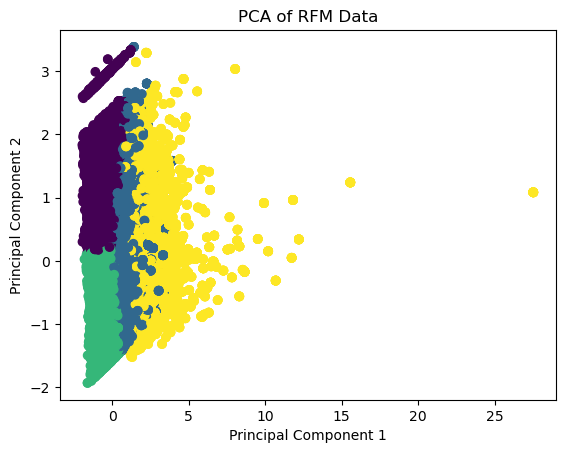

Davies-Bouldin Score: 5.912469556999174
Silhouette Score: 0.1614061966427755


In [2]:
# Import necessary librariesfrom datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd

# Set display options
pd.set_option('display.max_columns', None)  
pd.set_option('display.max_rows', 100) 
pd.set_option('max_colwidth', 100) 

# Load data
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# Merge data
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Aggregate by customer
data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Rename columns
data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)

# Convert boolean columns to integers
data['perfect_score'] = (data['average_review_score'] == 5).astype(int)
data['has_multiple_orders'] = (data['total_orders'] > 1).astype(int)

# Extract 'customer_unique_id' and 'order_purchase_timestamp'
timestamps = orders_reviews[['customer_unique_id', 'order_purchase_timestamp']]

# Join the aggregated DataFrame with the timestamps DataFrame
final_data = pd.merge(data, timestamps, on='customer_unique_id', how='inner')

# Select desired columns
final_data = final_data[['customer_unique_id', 'total_payment_value',
                         'total_products', 'perfect_score',
                         'has_multiple_orders', 'total_orders',  
                         'order_purchase_timestamp']]





# Convert 'order_purchase_timestamp' to datetime object
final_data['order_purchase_timestamp'] = pd.to_datetime(final_data['order_purchase_timestamp'])

# Calculate the last purchase date for each customer
final_data['last_purchase_date'] = final_data.groupby('customer_unique_id')['order_purchase_timestamp'].transform('max')

# Get the maximum transaction date
max_trans_date = final_data['order_purchase_timestamp'].max().date()

# Calculate 'Recency' for each customer
final_data['Recency'] = (max_trans_date - final_data['last_purchase_date'].dt.date).dt.days

# Calculate 'Frequency' and 'MonetaryValue' for each customer
final_data['Frequency'] = final_data['total_orders']
final_data['MonetaryValue'] = final_data['total_payment_value']

# Perform log transformation on 'MonetaryValue'
final_data['MonetaryValue_log'] = np.log(final_data['MonetaryValue'] + 1)  # Adding 1 to handle zero values

# Scaling the features
rfm_features = ['Recency', 'Frequency', 'MonetaryValue_log']
scaler = StandardScaler()
rfm_data_scaled = scaler.fit_transform(final_data[rfm_features])

# Clustering
kmeans = KMeans(n_clusters=4, random_state=42)  # Choose an appropriate number of clusters
final_data['RFM_Cluster'] = kmeans.fit_predict(rfm_data_scaled)

# Analyze the clusters
display(final_data.groupby('RFM_Cluster').agg({
    'Recency': ['mean', 'std'],
    'Frequency': ['mean', 'std'],
    'MonetaryValue': ['mean', 'std']
}).reset_index())

# Visualization of clusters using PCA
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(rfm_data_scaled)
principalDf = pd.DataFrame(data=principalComponents, columns=['PC1', 'PC2'])

plt.scatter(principalDf['PC1'], principalDf['PC2'], c=final_data['RFM_Cluster'])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of RFM Data')
plt.show()

# Davies-Bouldin Score
db_score = davies_bouldin_score(final_data[rfm_features], final_data['RFM_Cluster'])
print(f'Davies-Bouldin Score: {db_score}')

# Silhouette Score
silhouette_avg = silhouette_score(final_data[rfm_features], final_data['RFM_Cluster'])
print(f'Silhouette Score: {silhouette_avg}')



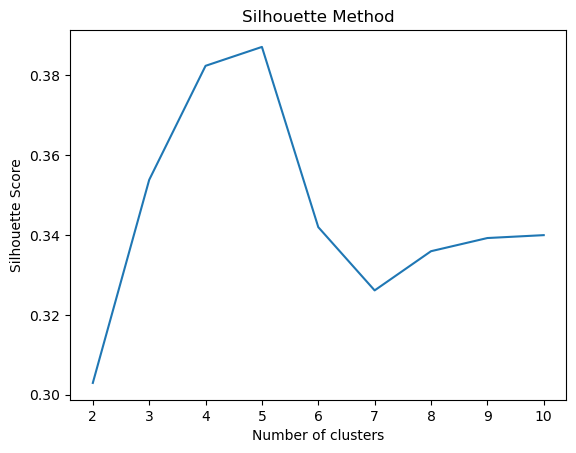

In [3]:
# Calculate Silhouette Score for different numbers of clusters
silhouette_scores = []
for i in range(2, 11): 
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(rfm_data_scaled)
    silhouette_avg = silhouette_score(rfm_data_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Plotting the Silhouette graph
plt.figure()
plt.plot(range(2, 11), silhouette_scores)
plt.title('Silhouette Method')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

## Résumé des Clusters

### Cluster 0

| Métrique | Valeur |
|----------|--------|
| Recency (mean, std) | 426.56, 88.54 |
| Frequency (mean, std) | 1.00, 0.02 |
| Monetary Value (mean, std) | 148.56, 141.82 |

**Interprétation**: High Recency, Low Frequency, Low Monetary Value: "Churning or At-Risk Customers"

---

### Cluster 1

| Métrique | Valeur |
|----------|--------|
| Recency (mean, std) | 208.70, 117.90 |
| Frequency (mean, std) | 1.00, 0.00 |
| Monetary Value (mean, std) | 1129.88, 3057.80 |

**Interprétation**: Moderate Recency, Low Frequency, High Monetary Value: "Potential High-Value One-Time Buyers"

---

### Cluster 2

| Métrique | Valeur |
|----------|--------|
| Recency (mean, std) | 230.68, 147.79 |
| Frequency (mean, std) | 2.24, 0.90 |
| Monetary Value (mean, std) | 891.78, 2469.36 |

**Interprétation**: Moderate Recency, High Frequency, High Monetary Value: "Loyal High-Value Customers"

---

### Cluster 3

| Métrique | Valeur |
|----------|--------|
| Recency (mean, std) | 147.01, 82.47 |
| Frequency (mean, std) | 1.00, 0.00 |
| Monetary Value (mean, std) | 103.79, 59.33 |

**Interprétation**: Low Recency, Low Frequency, Low Monetary Value: "New or Occasional Low-Value Customers"


## Limites de l'analyse RFM

Pour l'étude du dataset avec les 3% ou 2836 clients achetant à nouveau, les résultats des scores Davies-Bouldin et Silhouette sont respectivement de 0.897
et 0.373alors que sur l'ensemble du dataset il sont de 5.912 pour Davies-Bouldin et  0.161 pour le Silhouette Score.

L'analyse RFM est effectivement souvent plus pertinente pour les clients qui ont effectué plusieurs achats, car elle permet de capturer plus efficacement leur comportement d'achat. 

In [ ]:
CCl : le modèle RFM formé sur le sous-ensemble de 3% ne semble pas applicable au reste de la population. 

# Modélisation de la segmentation des données Olist 

In [ ]:
Business Context:
The better model depends on the specific business questions we are trying to answer. In order to focus on
customer lifetime value, the monetary value in the RFM model could be more useful. Focusing on
customer engagement, then the features in the second model like perfect_score and has_multiple_orders may offer more insights.

## clustering hiérarchique agglomératif

Initial DataFrame "data":


,total_payment_value,total_products,perfect_score,has_multiple_orders,customer_unique_id
0,141.90,1,1,0,0000366f3b9a7992bf8c76cfdf3221e2
1,27.19,1,0,0,0000b849f77a49e4a4ce2b2a4ca5be3f
2,86.22,1,0,0,0000f46a3911fa3c0805444483337064
3,43.62,1,0,0,0000f6ccb0745a6a4b88665a16c9f078
4,196.89,1,1,0,0004aac84e0df4da2b147fca70cf8255


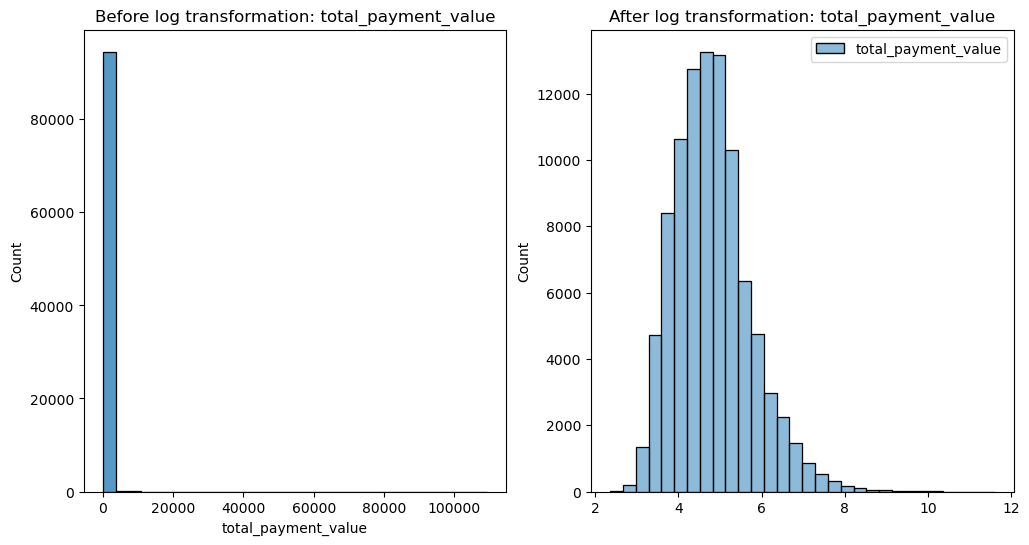

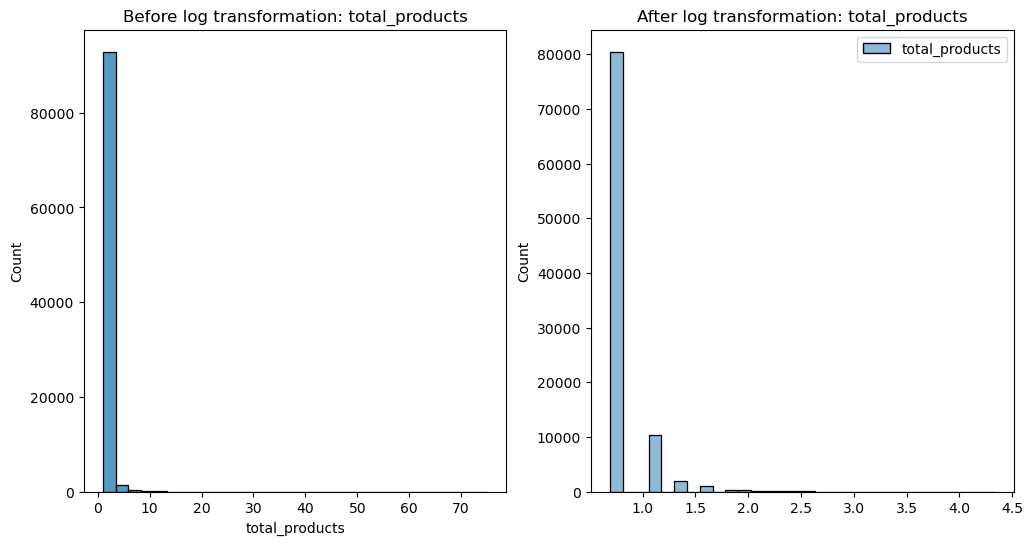

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.base import BaseEstimator, TransformerMixin
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

# Display all columns
pd.set_option('display.max_columns', None)

# Display all rows
pd.set_option('display.max_rows', None)

# Increase the width of each column to display more characters
pd.set_option('max_colwidth', 100)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans,AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import davies_bouldin_score

# Define a class for log transformation
class LogTransformer(BaseEstimator, TransformerMixin):
    """
    A custom transformer for logarithmic transformation.
    """
    def __init__(self, add_one=False):
        self.add_one = add_one

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if self.add_one:
            X = X + 1
        return np.log(X)

# Load and merge data
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# Merge dataframes
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Aggregate data by unique customer ID
customer_data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Rename columns for clarity
customer_data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)

# Convert boolean columns to integers for compatibility with k-means algorithm
customer_data['perfect_score'] = (customer_data['average_review_score'] == 5).astype(int)
customer_data['has_multiple_orders'] = (customer_data['total_orders'] > 1).astype(int)

# Copy data for further processing
features = ['total_payment_value', 'total_products', 'perfect_score', 'has_multiple_orders']
data = customer_data[features + ['customer_unique_id']].copy()
original_data = data.copy()

# Display the initial DataFrame
print('Initial DataFrame "data":')
display(original_data.head())

# Define numerical and categorical columns
num_cols = ['total_payment_value', 'total_products']
cat_cols = ['perfect_score', 'has_multiple_orders']

# Log transformation, imputation, and scaling
log_transformer = LogTransformer(add_one=True)

# Apply log transformation and visualize
for col in num_cols:
    original_col_data = original_data[col].copy()
    transformed_col_data = log_transformer.transform(original_data[[col]])

    # Visualize
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    sns.histplot(original_col_data, bins=30)
    plt.title(f"Before log transformation: {col}")

    plt.subplot(1, 2, 2)
    sns.histplot(transformed_col_data, bins=30)
    plt.title(f"After log transformation: {col}")

    plt.show()

    # Apply the transformation to the column
    original_data[col] = transformed_col_data

# Imputation
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

original_data[num_cols] = num_imputer.fit_transform(original_data[num_cols])
original_data[cat_cols] = cat_imputer.fit_transform(original_data[cat_cols])

# Scaling
scaler = StandardScaler()
data_scaled = scaler.fit_transform(original_data[features])

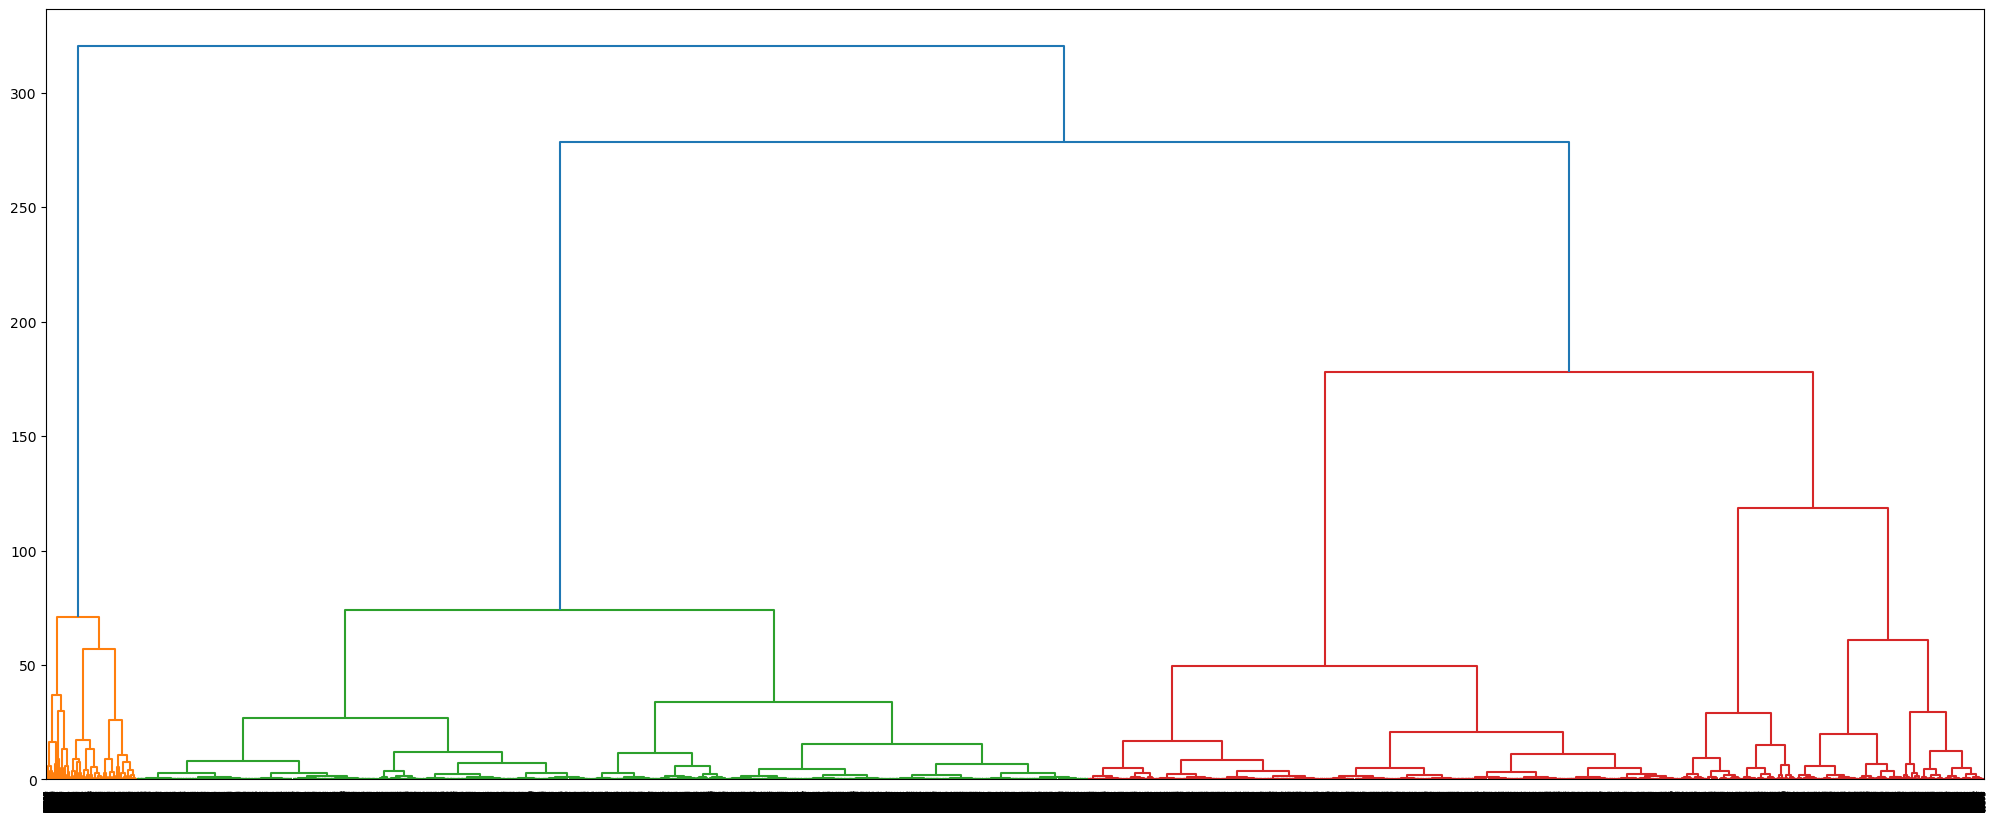

In [3]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt# Reducing the data size to 50%
from sklearn.decomposition import PCA
reduced_data = original_data.sample(frac=0.5, random_state=42)

# Scaling the reduced data
data_scaled = scaler.fit_transform(reduced_data[features])

# Dimension reduction using PCA
pca = PCA(n_components=2)
data_reduced = pca.fit_transform(data_scaled)

# Hierarchical clustering
Z = linkage(data_reduced, method='ward')

# Plotting the dendrogram
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)
plt.show()


interprétation du dendogramme : <br>
1. Identifier la ligne horizontale la plus longue qui n'est interrompue par aucune autre ligne horizontale.<br>
2. Tracer une ligne horizontale à travers cette ligne longue pour la couper.<br>
3. Compter le nombre de lignes verticales croisées par cette ligne horizontale tracée.<br>
<br><br>
Le nombre de lignes verticales croisées indique le nombre optimal de clusters à choisir.

Davies Bouldin Score for Agglomerative: 0.7566225061613814


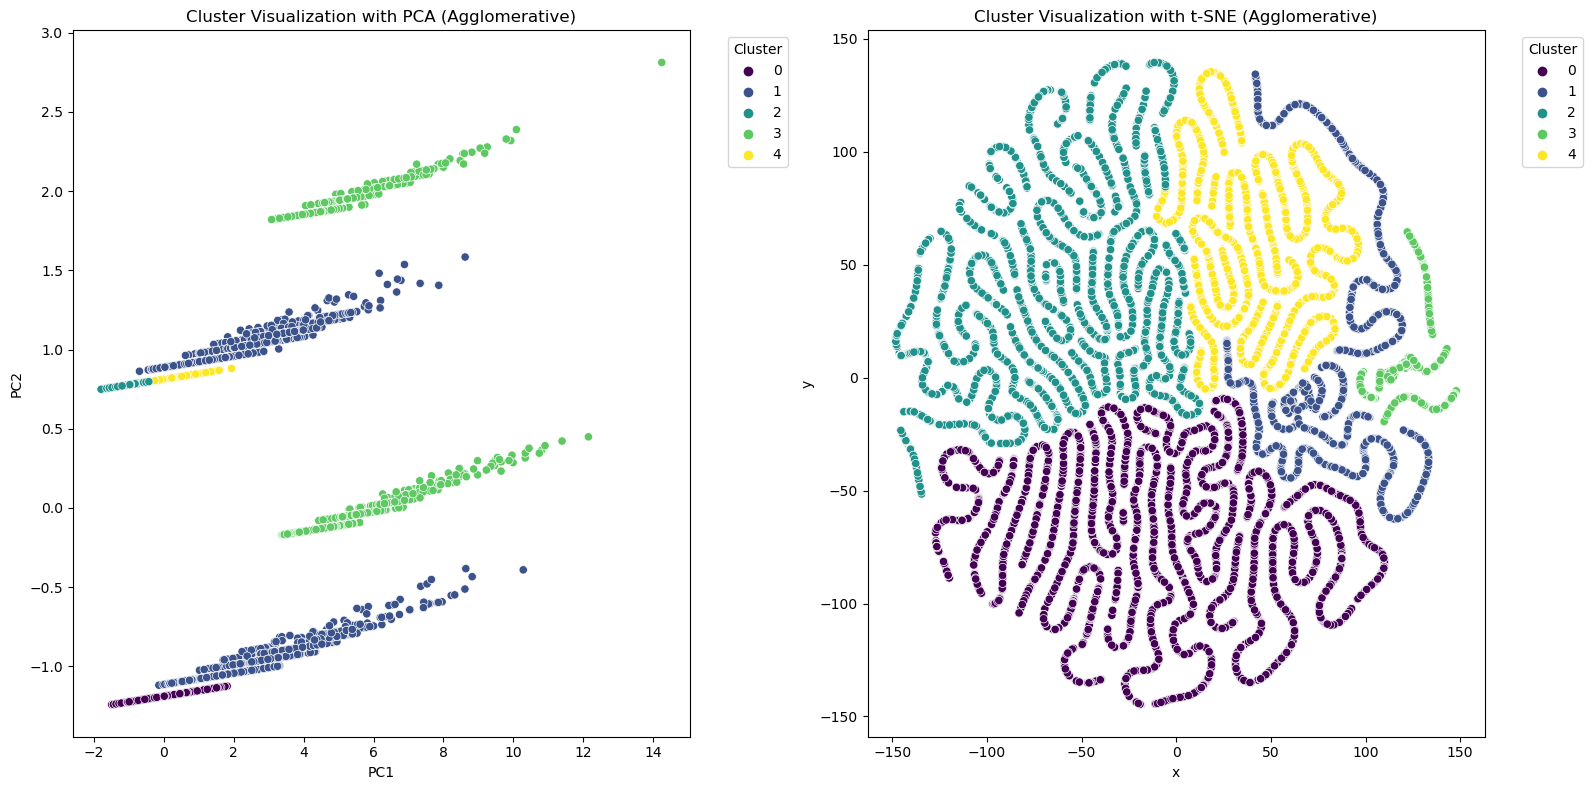

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans,AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import davies_bouldin_score
# Running PCA and storing the results
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_scaled)
df_pca = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

# Running t-SNE and storing the results
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(data_scaled)
df_tsne = pd.DataFrame(data=tsne_result, columns=['x', 'y'])

# Clustering with Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=5)
agg_clusters = agg_clustering.fit_predict(data_scaled)
agg_db_score = davies_bouldin_score(data_scaled, agg_clusters)

print("Davies Bouldin Score for Agglomerative:", agg_db_score)

# Adding clusters to PCA and t-SNE DataFrames
df_pca['agg_cluster'] = agg_clusters
df_tsne['agg_cluster'] = agg_clusters

# Plotting
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
sns.scatterplot(x='PC1', y='PC2', hue='agg_cluster', data=df_pca, palette='viridis', legend='full')
plt.title('Cluster Visualization with PCA (Agglomerative)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.subplot(1, 2, 2)
sns.scatterplot(x='x', y='y', hue='agg_cluster', data=df_tsne, palette='viridis', legend='full')
plt.title('Cluster Visualization with t-SNE (Agglomerative)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


## K-means et DBscan

Initial DataFrame "data":


,total_payment_value,total_products,perfect_score,has_multiple_orders,customer_unique_id
0,141.90,1,1,0,0000366f3b9a7992bf8c76cfdf3221e2
1,27.19,1,0,0,0000b849f77a49e4a4ce2b2a4ca5be3f
2,86.22,1,0,0,0000f46a3911fa3c0805444483337064
3,43.62,1,0,0,0000f6ccb0745a6a4b88665a16c9f078
4,196.89,1,1,0,0004aac84e0df4da2b147fca70cf8255


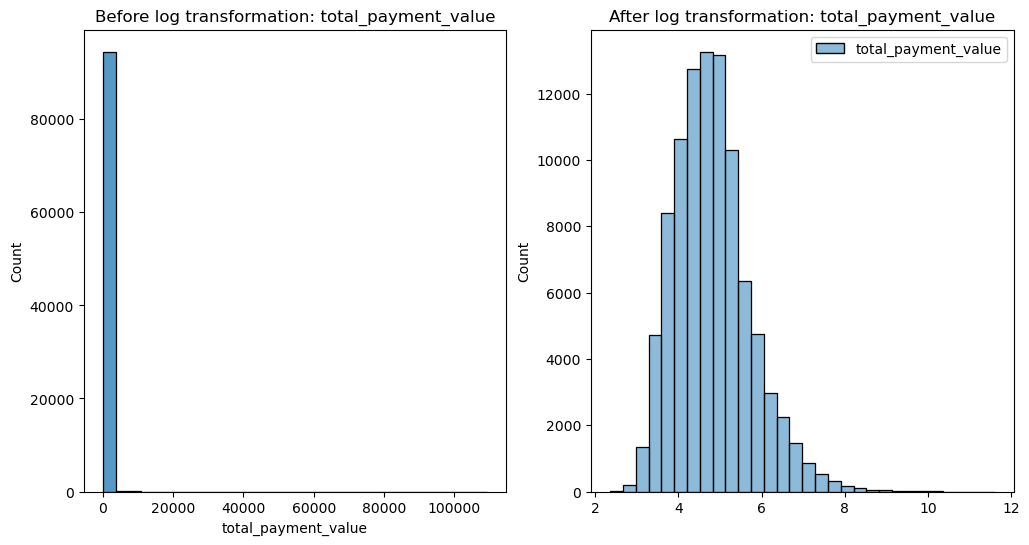

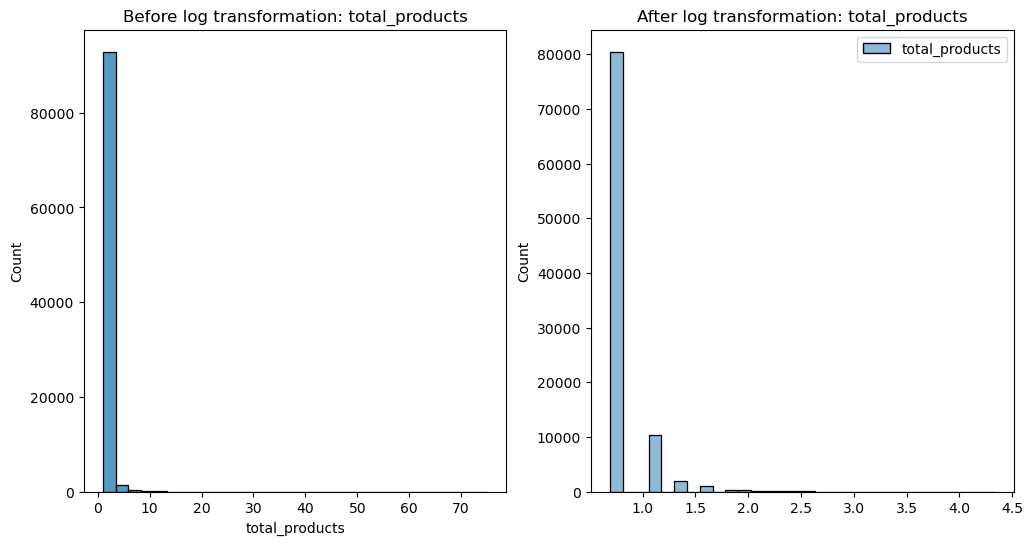

/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


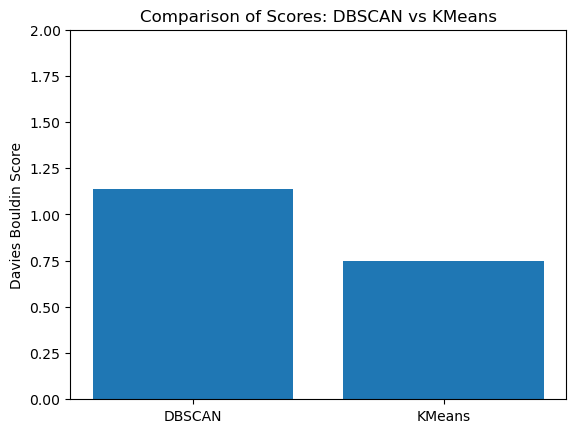

Davies Bouldin Score for DBSCAN: 1.1369018630773196
Davies Bouldin Score for KMeans: 0.7507581160540492


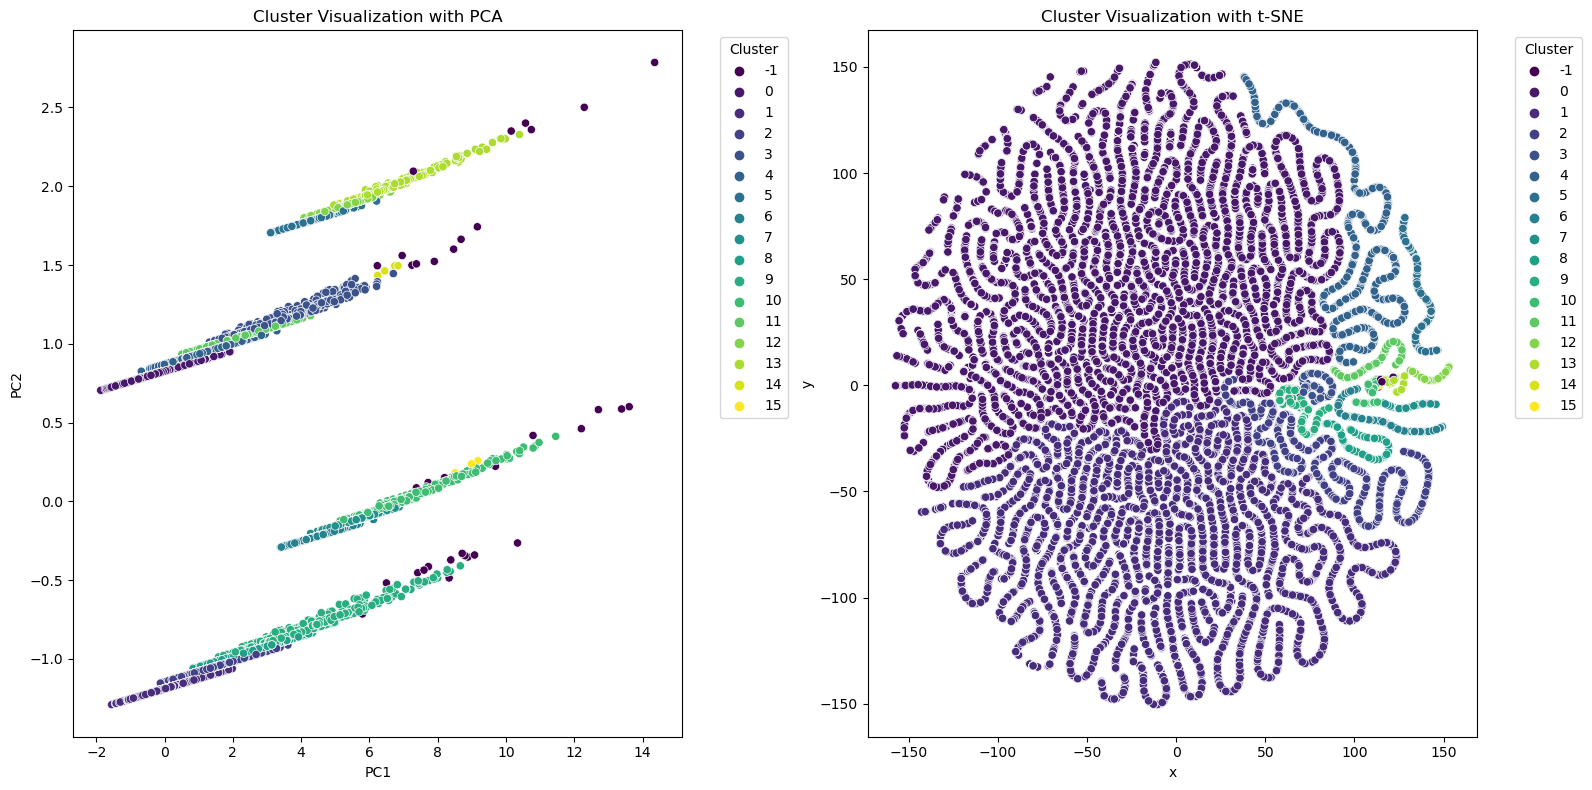

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import davies_bouldin_score

# Define a class for log transformation
class LogTransformer(BaseEstimator, TransformerMixin):
    """
    A custom transformer for logarithmic transformation.
    """
    def __init__(self, add_one=False):
        self.add_one = add_one

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if self.add_one:
            X = X + 1
        return np.log(X)

# Load and merge data
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# Merge dataframes
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Aggregate data by unique customer ID
customer_data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Rename columns for clarity
customer_data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)

# Convert boolean columns to integers for compatibility with k-means algorithm
customer_data['perfect_score'] = (customer_data['average_review_score'] == 5).astype(int)
customer_data['has_multiple_orders'] = (customer_data['total_orders'] > 1).astype(int)

# Copy data for further processing
features = ['total_payment_value', 'total_products', 'perfect_score', 'has_multiple_orders']
data = customer_data[features + ['customer_unique_id']].copy()
original_data = data.copy()

# Display the initial DataFrame
print('Initial DataFrame "data":')
display(original_data.head())

# Define numerical and categorical columns
num_cols = ['total_payment_value', 'total_products']
cat_cols = ['perfect_score', 'has_multiple_orders']

# Log transformation, imputation, and scaling
log_transformer = LogTransformer(add_one=True)

# Apply log transformation and visualize
for col in num_cols:
    original_col_data = original_data[col].copy()
    transformed_col_data = log_transformer.transform(original_data[[col]])

    # Visualize
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    sns.histplot(original_col_data, bins=30)
    plt.title(f"Before log transformation: {col}")

    plt.subplot(1, 2, 2)
    sns.histplot(transformed_col_data, bins=30)
    plt.title(f"After log transformation: {col}")

    plt.show()

    # Apply the transformation to the column
    original_data[col] = transformed_col_data

# Imputation
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

original_data[num_cols] = num_imputer.fit_transform(original_data[num_cols])
original_data[cat_cols] = cat_imputer.fit_transform(original_data[cat_cols])

# Scaling
scaler = StandardScaler()
data_scaled = scaler.fit_transform(original_data[features])

# Clustering with DBSCAN
data_sample = pd.DataFrame(data_scaled, columns=features).sample(frac=0.1, random_state=42)
best_score = float('inf')
best_params = None

for eps in [0.1, 0.5, 1.0]:
    for min_samples in [5, 10, 20]:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan.fit(data_sample)

        if len(set(dbscan.labels_)) == 1 and -1 in set(dbscan.labels_):
            continue

        score = davies_bouldin_score(data_sample, dbscan.labels_)

        if score < best_score:
            best_score = score
            best_params = {'eps': eps, 'min_samples': min_samples}

dbscan = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
clusters = dbscan.fit_predict(data_scaled)
db_score = davies_bouldin_score(data_scaled, clusters)

# Clustering with KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data_scaled)
kmeans_clusters = kmeans.predict(data_scaled)
kmeans_db_score = davies_bouldin_score(data_scaled, kmeans_clusters)

# Compare clustering scores
plt.bar(['DBSCAN', 'KMeans'], [db_score, kmeans_db_score])
plt.ylabel('Davies Bouldin Score')
plt.title('Comparison of Scores: DBSCAN vs KMeans')
plt.ylim(0, 2)
plt.show()

print("Davies Bouldin Score for DBSCAN:", db_score)
print("Davies Bouldin Score for KMeans:", kmeans_db_score)

# Visualization with PCA and t-SNE
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)

tsne = TSNE(n_components=2, random_state=42)
data_tsne = tsne.fit_transform(data_scaled)

df_pca = pd.DataFrame(data_pca, columns=['PC1', 'PC2'])
df_pca['cluster'] = clusters

df_tsne = pd.DataFrame(data_tsne, columns=['x', 'y'])
df_tsne['cluster'] = clusters

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
sns.scatterplot(x='PC1', y='PC2', hue='cluster', data=df_pca, palette='viridis', legend="full")
plt.title('Cluster Visualization with PCA')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.subplot(1, 2, 2)
sns.scatterplot(x='x', y='y', hue='cluster', data=df_tsne, palette='viridis', legend="full")
plt.title('Cluster Visualization with t-SNE')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Le score de Davies-Bouldin est une mesure d'évaluation de la qualité du clustering, où des valeurs plus basses indiquent un meilleur regroupement. Un score plus faible signifie que les clusters sont bien séparés et que les points à l'intérieur de chaque cluster sont proches les uns des autres.<br>
Dans notre cas, le score de Davies-Bouldin pour KMeans est de 0.751, tandis que pour DBSCAN, il est de 1.137. Davies Bouldin Score pour le clustering Agglomeratif: Davies Bouldin Score for Agglomerative: 0.7566225061613814 (avec réduction de dimensionnalité et échantillonnage du dataset, car met beaucoup de temps à tourner). <br>
    Cela suggère que KMeans réalise un clustering plus cohérent et bien séparé par rapport à DBSCAN ou le clustering agglomératif selon cette métrique.<br>
En ce qui concerne le graphique t-SNE pour DBSCAN montre 15 clusters qui sont difficilement identifiables<br>
Dans l'ensemble, compte tenu des scores de Davies-Bouldin et des visualisations t-SNE, il semble que KMeans puisse être une meilleure option pour le clustering </p> 


In [3]:
# Display the first few rows of the DataFrame
# Convert the NumPy array to a Pandas DataFrame
data_scaled_df = pd.DataFrame(data_scaled, columns=features)

# Display the first few rows of the DataFrame
print("The first few rows of data_scaled:")
display(data_scaled_df.head())

# Display descriptive statistics
print("Descriptive statistics of the dataset before logarithm transformation and scaling:")
display(data.describe())

The first few rows of data_scaled:


,total_payment_value,total_products,perfect_score,has_multiple_orders
0,0.161562,-0.371137,0.857779,-0.176735
1,-1.623266,-0.371137,-1.165802,-0.176735
2,-0.381318,-0.371137,-1.165802,-0.176735
3,-1.118319,-0.371137,-1.165802,-0.176735
4,0.519550,-0.371137,0.857779,-0.176735


Descriptive statistics of the dataset before logarithm transformation and scaling:


,total_payment_value,total_products,perfect_score,has_multiple_orders
count,94720.000000,94720.000000,94720.000000,94720.000000
mean,213.132693,1.238693,0.576109,0.030289
std,630.134487,0.849490,0.494176,0.171383
min,9.590000,1.000000,0.000000,0.000000
25%,63.900000,1.000000,0.000000,0.000000
50%,113.150000,1.000000,1.000000,0.000000
75%,202.965000,1.000000,1.000000,0.000000
max,109312.640000,75.000000,1.000000,1.000000


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Interprétation des statistiques descriptives<br>
total_payment_value: La moyenne est environ 213 avec un écart-type de 630, ce qui indique une grande variabilité. Les 25 % les plus bas sont en dessous de 64, et les 25 % les plus élevés sont au-dessus de 203. Le minimum est de 9.59 et le maximum est de 109312.64, ce qui suggère une distribution très asymétrique.<br>
total_products: La moyenne est d'environ 1.24 avec un écart-type d'environ 0.85, ce qui indique une variabilité modérée. Le minimum est de 1 et le maximum est de 75, ce qui suggère également une distribution asymétrique.<br>
perfect_score: La moyenne est d'environ 0.576, ce qui indique que la majorité des scores sont parfaits (probablement indiquant une bonne expérience utilisateur ou produit). Le minimum et le maximum sont 0 et 1, indiquant une variable booléenne.<br>
has_multiple_orders: La moyenne est très faible (0.03), ce qui suggère que très peu de clients ont passé plusieurs commandes. C'est également une variable booléenne.</p>

# choix du modèle k-means et ajustement de la pipeline

/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_

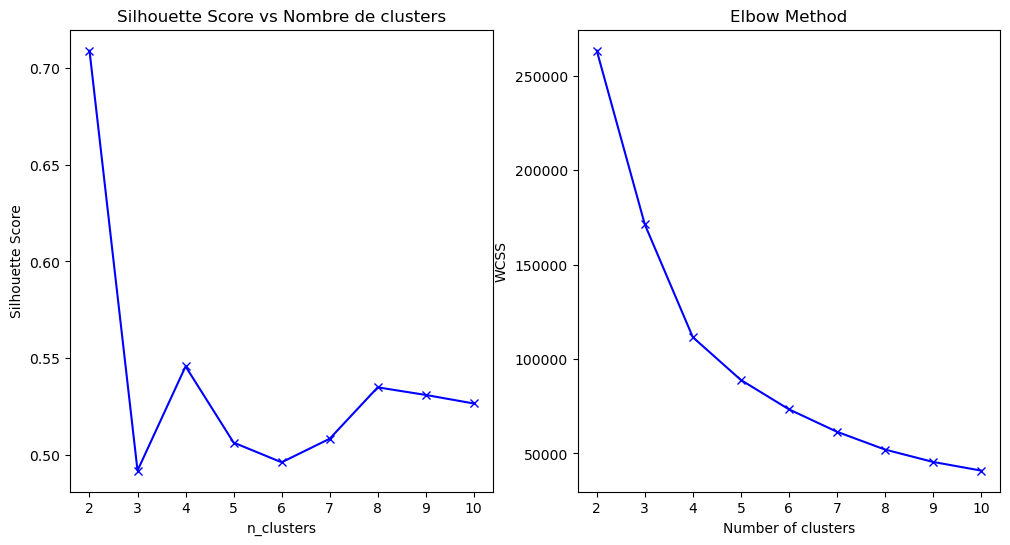

In [5]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.base import BaseEstimator, TransformerMixin
from scipy import stats
# Choosing the model: K-means
# Calculating silhouette scores and WCSS (Within-Cluster Sum of Squares)
silhouette_scores = []
wcss = []

for n_clusters in range(2, 11):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(data_scaled)
    labels = kmeans.labels_
    
    # Calculating the silhouette score
    silhouette_scores.append(silhouette_score(data_scaled, labels))
    
    # Retrieving WCSS
    wcss.append(kmeans.inertia_)
    
# Displaying the graphs side by side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(range(2, 11), silhouette_scores, 'bx-')
plt.title('Silhouette Score vs Nombre de clusters')
plt.xlabel('n_clusters')
plt.ylabel('Silhouette Score')

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), wcss, 'bx-')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')

plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Nous observons une amélioration du score silhouette lorsque le nombre de clusters est fixé à 4, même si le nombre optimal selon cette métrique serait de 2. De plus, la méthode du coude indique également un point d'inflexion à 4 clusters. Afin de progresser dans notre analyse, nous choisirons donc de configurer notre modèle avec 4 clusters.</p> 



/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


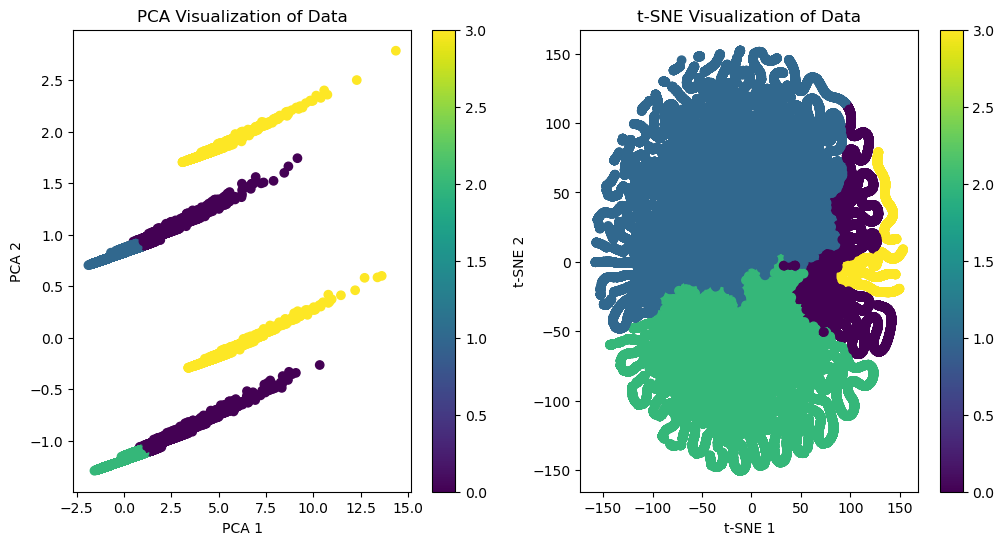

In [6]:
# Import necessary libraries
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Apply KMeans and visualize with PCA and t-SNE
def cluster_and_visualize(data_scaled):
    """
    Perform KMeans clustering and visualize data using PCA and t-SNE.

    Parameters:
    - data_scaled: Scaled data for clustering.

    Returns: None
    """
    # Determine and fit with the optimal number of clusters, which is 4
    kmeans = KMeans(n_clusters=4, random_state=42)
    data['cluster'] = kmeans.fit_predict(data_scaled)

    # Visualize data with PCA
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(data_scaled)

    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.scatter(pca_result[:, 0], pca_result[:, 1], c=data['cluster'], cmap='viridis')
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.title('PCA Visualization of Data')
    plt.colorbar()

    # Visualize data with t-SNE
    tsne = TSNE(n_components=2, random_state=42)
    tsne_result = tsne.fit_transform(data_scaled)

    plt.subplot(1, 2, 2)
    plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c=data['cluster'], cmap='viridis')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.title('t-SNE Visualization of Data')
    plt.colorbar()

    plt.show()

# Call the function with your scaled data
cluster_and_visualize(data_scaled)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> La visualisation t-SNE nous permet d'identifier 4 clusters distincts
</p> 



## apercu des caracteristiques des clusters

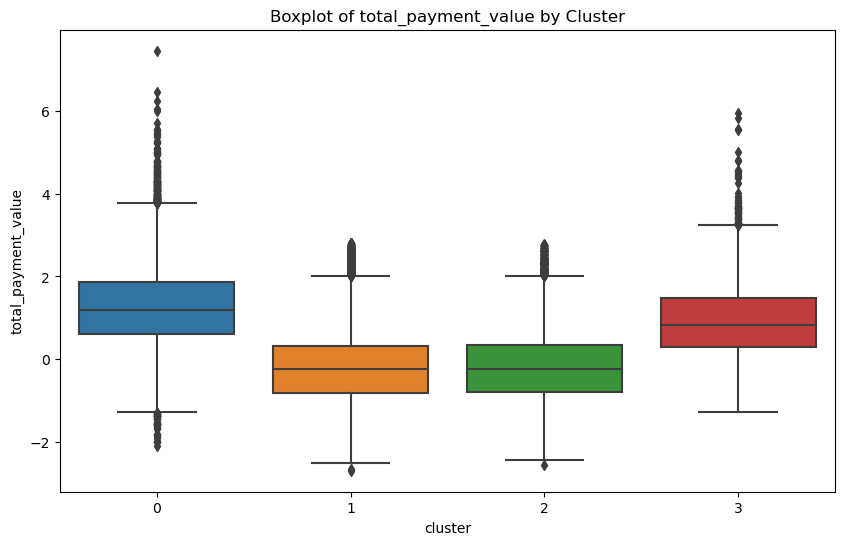

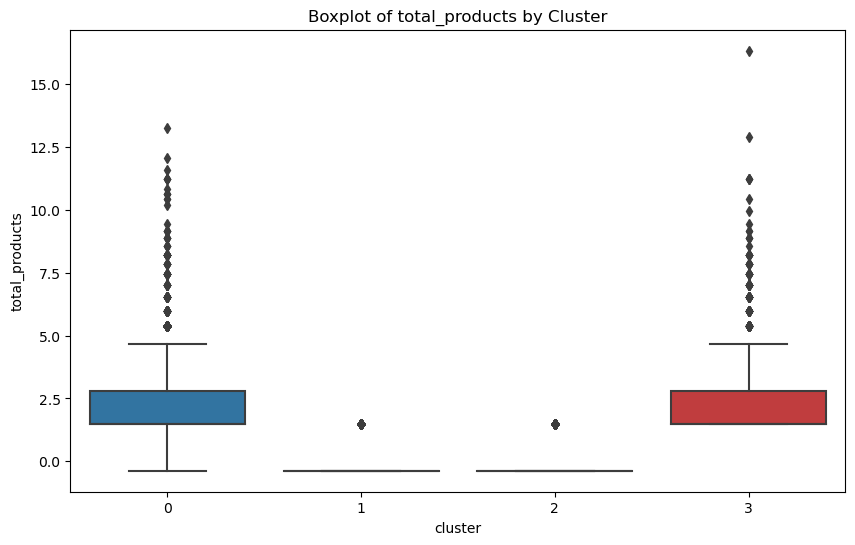

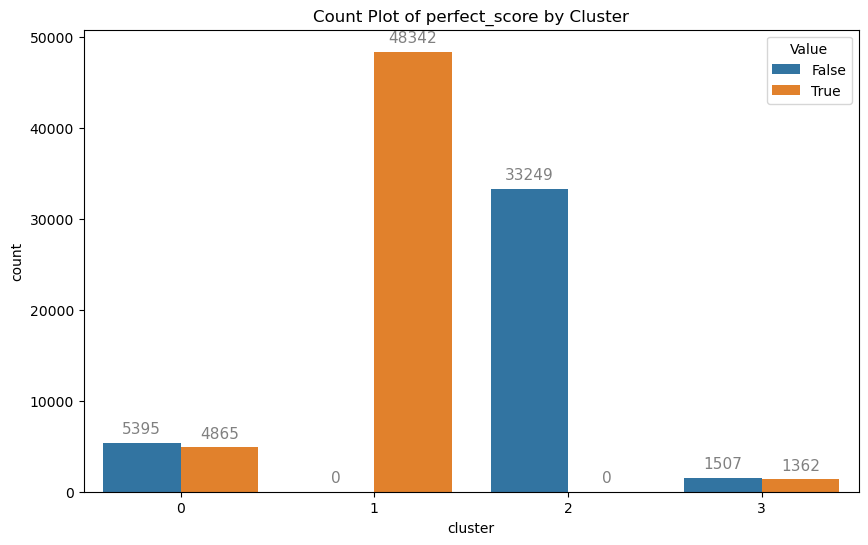

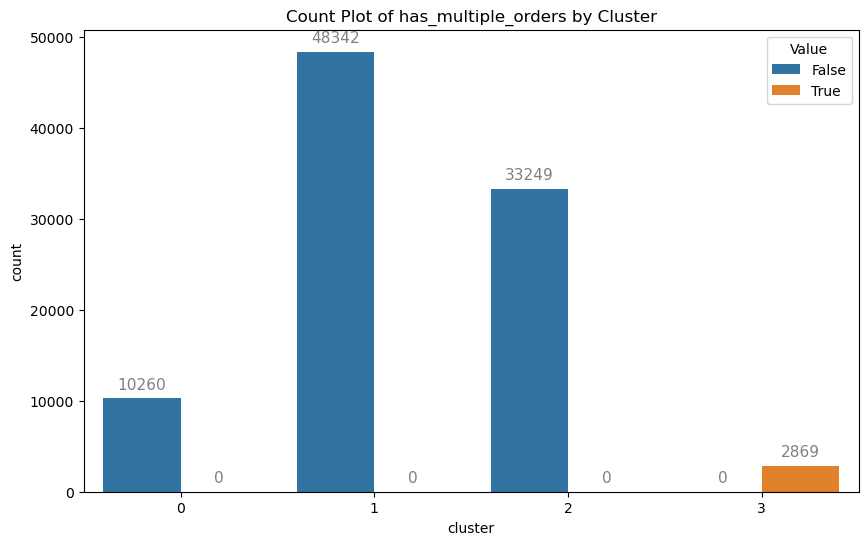

In [7]:
# Copy the original boolean columns
original_bool_columns = data[cat_cols].copy()

# Apply the same imputation as in your pipeline for consistency
imputer = SimpleImputer(strategy='most_frequent')
original_bool_columns = imputer.fit_transform(original_bool_columns)

# Replace the boolean columns in the transformed data with the original boolean columns
X_transformed_df = pd.DataFrame(data_scaled, columns=features)
X_transformed_df[cat_cols] = original_bool_columns

# Add cluster labels
X_transformed_df['cluster'] = kmeans_clusters

# Use X_transformed_df for visualization
features_with_clusters = X_transformed_df.copy()

# Plot graphs for continuous and binary variables
for feature in features:
    plt.figure(figsize=(10, 6))
    if feature in ['total_payment_value', 'total_products']:
        # Use a boxplot for continuous variables
        ax = sns.boxplot(x='cluster', y=feature, data=features_with_clusters)
        plt.title(f'Boxplot of {feature} by Cluster')
    else:
        # Use a countplot for binary variables
        ax = sns.countplot(x='cluster', hue=feature, data=features_with_clusters)
        plt.title(f'Count Plot of {feature} by Cluster')
        
        # Customize the legend to replace True and False
        legend_labels, _= ax.get_legend_handles_labels()
        ax.legend(legend_labels, ['False', 'True'], title='Value')
        
        # Add the sample count above the bars
        for p in ax.patches:
            ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=11, color='gray', xytext=(0, 10),
                        textcoords='offset points')
        
    plt.show()

In [8]:
# Define the list of features
features = ['total_payment_value', 'total_products', 'perfect_score', 'has_multiple_orders']

# Calculate the means and counts for each cluster
features_with_clusters = X_transformed_df[features + ['cluster']]
cluster_characteristics = features_with_clusters.groupby('cluster').mean()
cluster_characteristics['Count'] = features_with_clusters['cluster'].value_counts()

# Print cluster characteristics
print("Cluster characteristics:")
display(cluster_characteristics)

print("\n" + "="*50 + "\n")

# Display data for each cluster
for cluster_num in cluster_characteristics.index:
    cluster_data = features_with_clusters[features_with_clusters['cluster'] == cluster_num]
    print(f"Cluster {cluster_num}:")
    display(cluster_data.head())
    print("\n" + "="*50 + "\n")  # Line to separate clusters

Cluster characteristics:


,total_payment_value,total_products,perfect_score,has_multiple_orders,Count
cluster,,,,,
0,1.305660,2.021042,0.474172,0.0,10260
1,-0.202944,-0.338079,1.000000,0.0,48342
2,-0.189953,-0.340587,0.000000,0.0,33249
3,0.951687,2.416073,0.474730,1.0,2869




Cluster 0:


,total_payment_value,total_products,perfect_score,has_multiple_orders,cluster
7,2.108377,1.489263,0,0,0
18,1.573136,1.489263,0,0,0
22,2.709894,3.833090,1,0,0
25,1.360879,1.489263,0,0,0
32,0.219562,1.489263,1,0,0




Cluster 1:


,total_payment_value,total_products,perfect_score,has_multiple_orders,cluster
0,0.161562,-0.371137,1,0,1
4,0.519550,-0.371137,1,0,1
11,0.034105,-0.371137,1,0,1
12,-0.710415,-0.371137,1,0,1
16,-1.554839,-0.371137,1,0,1




Cluster 2:


,total_payment_value,total_products,perfect_score,has_multiple_orders,cluster
1,-1.623266,-0.371137,0,0,2
2,-0.381318,-0.371137,0,0,2
3,-1.118319,-0.371137,0,0,2
5,0.339365,-0.371137,0,0,2
6,-1.342814,-0.371137,0,0,2




Cluster 3:


,total_payment_value,total_products,perfect_score,has_multiple_orders,cluster
105,1.163303,1.489263,1,1,3
122,0.205457,1.489263,0,1,3
142,0.394266,2.809238,0,1,3
245,0.007785,1.489263,0,1,3
307,0.791433,3.833090,0,1,3


/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


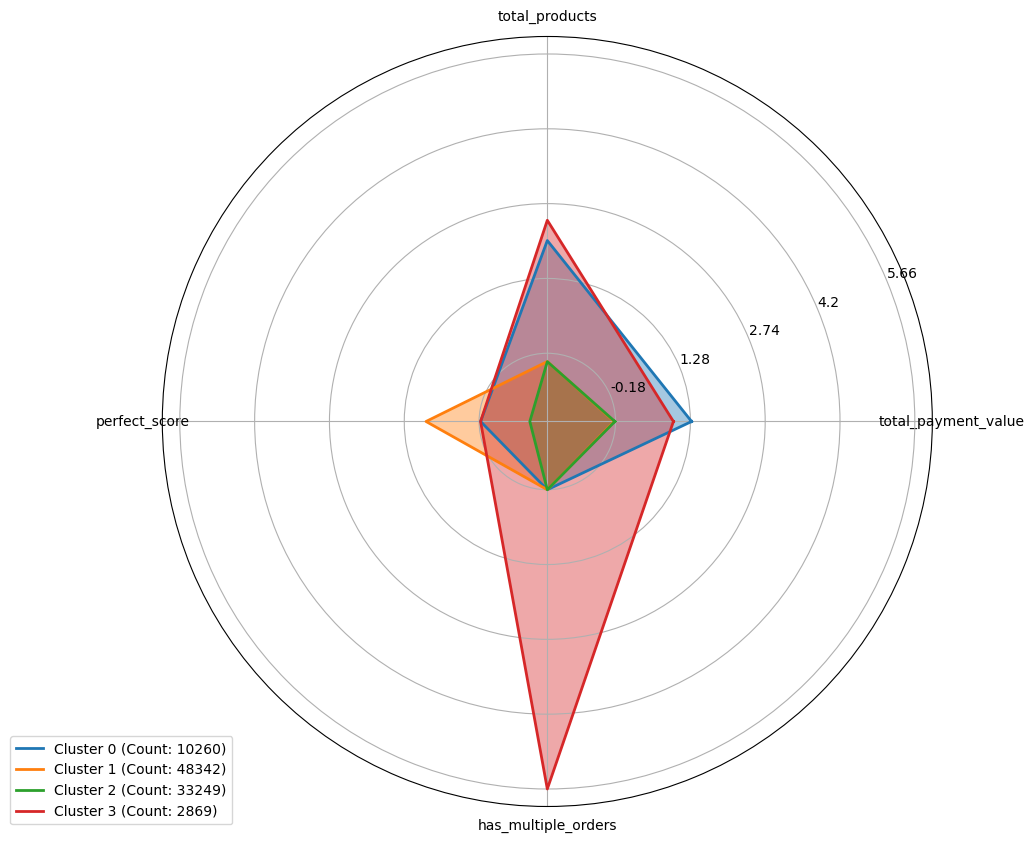

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import pi

# Predict cluster labels
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans = KMeans(n_clusters=4, random_state=42)
cluster_labels = kmeans.fit_predict(data_scaled)  # Fit and predict in one step


# Combine scaled data with cluster labels
data_scaled_with_clusters = np.column_stack((data_scaled, cluster_labels))
features_with_clusters_scaled = pd.DataFrame(data_scaled_with_clusters, columns=features + ['cluster'])

# Calculate cluster characteristics
cluster_characteristics_scaled = features_with_clusters_scaled.groupby('cluster').mean()
cluster_characteristics_scaled['Count'] = features_with_clusters_scaled['cluster'].value_counts()

# Calculate min and max values for each feature among clusters
min_values = cluster_characteristics_scaled.min()
max_values = cluster_characteristics_scaled.max()

# Determine y-axis scales for each feature
yticks = {}
for feature in cluster_characteristics_scaled.columns[:-1]:  # excluding the "Count" column
    yticks[feature] = np.linspace(min_values[feature], max_values[feature], 5)

# Create a radar plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, polar=True)

# Angles for each axis
angles = [n / float(len(cluster_characteristics_scaled.columns[:-1])) * 2 * pi for n in range(len(cluster_characteristics_scaled.columns[:-1]))]
angles += angles[:1]

# Add each feature to the radar axis
plt.xticks(angles[:-1], cluster_characteristics_scaled.columns[:-1])

# Plot data for each cluster
for i, row in cluster_characteristics_scaled.iterrows():
    values = row[:-1].values.flatten().tolist()  # excluding the "Count" value
    values += values[:1]
    count = int(row['Count'])  # number of elements in the cluster
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f"Cluster {int(i)} (Count: {count})")
    ax.fill(angles, values, alpha=0.4)

# Configure y-axis tick scales for each feature
for feature, scales in yticks.items():
    ax.set_yticks(scales)
    ax.set_yticklabels([str(round(s, 2)) for s in scales])

ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Comportements et préférences des clients: <br>
Cluster 0 (10260clients) : Gros acheteurs occasionnels qui dépensent beaucoup mais ont une satisfaction modérée. <br>
Cluster 1 (48342 clients) : Petits acheteurs occasionnels avec des dépenses limitées, mais très satisfaits de leurs achats. <br>
Cluster 2 (33249 clients) : Petits acheteurs occasionnels qui dépensent peu mais ont une très bonne satisfaction<br>
Cluster 3 (2869 clients) : Gros acheteurs avec plus d’une commande avec une satisfaction modérée<br><br>
Gros acheteurs occasionnels qui dépensent beaucoup mais ont une satisfaction modérée : Proposer des offres groupées de produits de haute qualité pour augmenter la satisfaction et maximiser la dépense.<br>
Petits acheteurs occasionnels avec des dépenses limitées, mais très satisfaits : Envoyer des e-mails de remerciement contenant des codes de réduction pour encourager de futurs achats.<br>
Petits acheteurs occasionnels avec des dépenses limitées, ont une satisfaction faible : Envoyer des enquêtes de satisfaction avec des incitations pour recueillir des retours et améliorer l'expérience client.<br>
Gros acheteurs avec plus d’une commande et une satisfaction modérée : Mettre en place un programme de fidélité offrant des avantages exclusifs pour encourager des achats récurrents et augmenter la satisfaction.

</p> 




## pipeline ajustée

/Users/laureagrech/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Davies Bouldin Score for KMeans: 0.7507581160540492


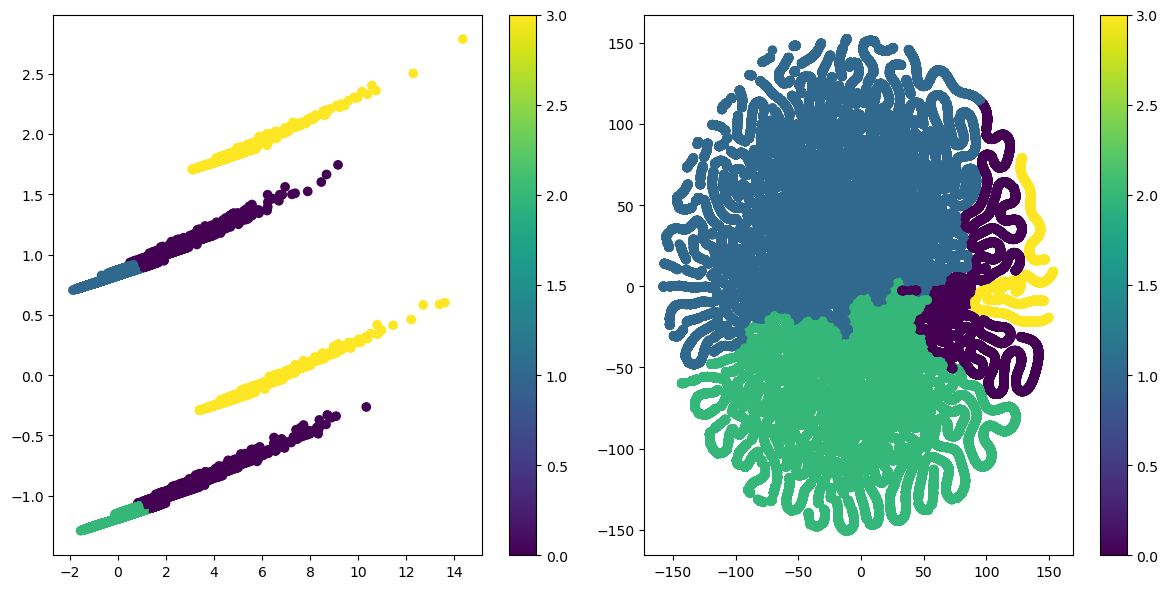

In [11]:
# Import statements
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Define columns and features
num_cols = ['total_payment_value', 'total_products']
cat_cols = ['perfect_score', 'has_multiple_orders']
features = num_cols + cat_cols

# Data
X = data[features]

# Logarithmic transformation
class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, add_one=False):
        self.add_one = add_one

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if self.add_one:
            X = X + 1
        return np.log(X)

# Pipelines
num_pipeline = Pipeline([
    ('log_transformer', LogTransformer(add_one=True)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clusterer', KMeans(n_clusters=4, random_state=42))
])

# Fitting and prediction
final_pipeline.fit(X)
labels = final_pipeline.named_steps['clusterer'].labels_
X_transformed = final_pipeline.named_steps['preprocessor'].transform(X)

# Evaluation
db_score = davies_bouldin_score(X_transformed, labels)
print("Davies Bouldin Score for KMeans:", db_score)

# Visualization
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_transformed)
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(X_transformed)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap='viridis')
plt.colorbar()
plt.subplot(1, 2, 2)
plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c=labels, cmap='viridis')
plt.colorbar()

plt.tight_layout()
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Comportements et préférences des clients: <br>
Ce code prépare un pipeline de traitement des données et de clustering pour l'ensemble de données e-commerce Olist. <br> 
Il utilise une transformation logarithmique, impute les valeurs manquantes et normalise les données avant de les soumettre à un modèle KMeans pour le clustering. <br>
Le code évalue ensuite la qualité du clustering avec le score de Davies-Bouldin et visualise les clusters à l'aide de PCA et de t-SNE. <br>
Ce pipeline aide à segmenter les clients en quatre groupes distincts basés sur leurs comportements d'achat.
</p> 

